# Stats 161 Midterm Project

## Data import

We select **24 consecutive weeks of Polymarket data, from January 1 to June 17, 2026**, to study wallet trading behavior. All dates and timestamps use UTC.


### 1. Setup


In [1]:
import pandas as pd
import requests

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from io import BytesIO


### 2. Dates and access settings


In [2]:
start_date = "2026-01-01"
end_date = "2026-06-17"
dates = pd.date_range(start_date, end_date, freq="D", tz="UTC")

base_url = "https://d1yyqbluk0oz0t.cloudfront.net"
course_password = 'PolymarketData2026!'


### 3. Wallet trades

We combine the 168 daily trade files into `wallet_trades`, keeping all wallets and all eight original variables. Each row is a recorded fill; one order may produce multiple fills.

| Variable | Description |
|---|---|
| `wallet` | Pseudonymous wallet ID, consistent across daily files. |
| `market` | Market slug; links to `markets.slug`. |
| `time` | Fill timestamp in UTC. |
| `side` | BUY or SELL for the recorded wallet. |
| `outcome` | Traded outcome, such as Yes, No, Up, Down, or a team name. |
| `price` | Execution price per share. |
| `size` | Number of shares traded. |
| `dollars` | Recorded dollar value of the fill. |


In [3]:
session = requests.Session()
session.auth = ("polymarketdatabase", course_password)
daily_trades = []

for day in dates:
    date_string = day.strftime("%Y-%m-%d")
    url = f"{base_url}/wallet_trades/trades-{date_string}.parquet"

    response = session.get(url, timeout=120)
    response.raise_for_status()
    day_trades = pd.read_parquet(BytesIO(response.content), dtype_backend="pyarrow")
    day_trades["time"] = pd.to_datetime(day_trades["time"], utc=True)

    # Check the file date.
    assert len(day_trades) > 0, f"Empty file: {date_string}"
    assert day_trades["time"].min().date() == day.date(), f"Unexpected date: {date_string}"
    assert day_trades["time"].max().date() == day.date(), f"Unexpected date: {date_string}"

    daily_trades.append(day_trades)
    if len(daily_trades) % 28 == 0:
        print(f"Loaded {len(daily_trades)} of {len(dates)} daily files.")

wallet_trades = pd.concat(daily_trades, ignore_index=True)
session.close()
del daily_trades, day_trades, response

print(f"Wallet trades imported: {len(wallet_trades):,} rows.")


Loaded 28 of 168 daily files.
Loaded 56 of 168 daily files.
Loaded 84 of 168 daily files.
Loaded 112 of 168 daily files.
Loaded 140 of 168 daily files.
Loaded 168 of 168 daily files.
Wallet trades imported: 56,738,552 rows.


### 4. Related market data

We import market, event, and settlement records for the markets in `wallet_trades`. All original columns are retained; key variables are listed below.

| DataFrame | Content | Key variables |
|---|---|---|
| `markets` | Market questions, outcome labels, and parent events. | `slug`, `title`, `event_slug`, `condition_id`, `outcomes`, `token_ids`, `start_date`, `end_date` |
| `events` | Event titles, descriptions, and scheduled dates. | `slug`, `title`, `description`, `start_date`, `end_date` |
| `resolutions` | Available settlement records. | `market_slug`, `resolved_yes`, `price_at_close`, `resolved_at` |

**Links:** `wallet_trades.market` → `markets.slug`; `markets.event_slug` → `events.slug`; `resolutions.market_slug` → `markets.slug`.

Market prices and volumes in the metadata reflect the current stored snapshot. Interpret resolution labels using the market's actual outcome labels.


In [4]:
database_url = URL.create(
    "postgresql+psycopg2",
    username="polymarketdatabase.merbqatlxbrcvtbnuaqe",
    password=course_password,
    host="aws-0-us-west-2.pooler.supabase.com",
    port=6543,
    database="postgres",
)

engine = create_engine(
    database_url,
    connect_args={"sslmode": "require", "connect_timeout": 20},
    execution_options={"postgresql_readonly": True},
)

market_slugs = wallet_trades["market"].dropna().unique().tolist()

with engine.connect() as connection:
    markets = pd.read_sql_query(
        text("SELECT * FROM public.markets WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )
    resolutions = pd.read_sql_query(
        text("SELECT * FROM public.resolutions WHERE market_slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )


In [5]:
event_slugs = markets["event_slug"].dropna().unique().tolist()

with engine.connect() as connection:
    events = pd.read_sql_query(
        text("SELECT * FROM public.events WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": event_slugs},
    )

engine.dispose()


### 5. Import check

Confirm the row and column counts, and report traded markets without matching catalog metadata.


In [6]:
for name, data in [("wallet_trades", wallet_trades), ("markets", markets),
                   ("events", events), ("resolutions", resolutions)]:
    print(f"{name}: {len(data):,} rows, {len(data.columns)} columns")

missing_market_slugs = set(market_slugs) - set(markets["slug"])
print(f"Traded market slugs without catalog metadata: {len(missing_market_slugs):,}")
print(f"Study period: {start_date} through {end_date} (UTC)")


wallet_trades: 56,738,552 rows, 8 columns
markets: 146,182 rows, 25 columns
events: 59,566 rows, 13 columns
resolutions: 31,893 rows, 6 columns
Traded market slugs without catalog metadata: 66
Study period: 2026-01-01 through 2026-06-17 (UTC)


## Data Cleaning

### 1. Check data quality

Check missing values, trade fields, recorded amounts (tolerance: $0.01), repeated rows, and market links. Counts can overlap.


In [7]:
missing_values = wallet_trades.isna().any(axis=1)
invalid_side = ~wallet_trades["side"].isin(["BUY", "SELL"])
invalid_price = ~wallet_trades["price"].between(0, 1)
negative_size = wallet_trades["size"] < 0
negative_dollars = wallet_trades["dollars"] < 0
amount_mismatch = (
    wallet_trades["dollars"] - wallet_trades["price"] * wallet_trades["size"]
).abs() > 0.01
repeated_rows = wallet_trades.duplicated()
missing_metadata = ~wallet_trades["market"].isin(markets["slug"])

quality_check = pd.Series({
    "Missing values in any trade column": missing_values.sum(),
    "Side outside BUY / SELL": invalid_side.sum(),
    "Price outside [0, 1]": invalid_price.sum(),
    "Negative shares": negative_size.sum(),
    "Negative dollar value": negative_dollars.sum(),
    "Dollar difference above $0.01": amount_mismatch.sum(),
    "Repeated rows after the first": repeated_rows.sum(),
    "Trades without market metadata": missing_metadata.sum(),
}, name="Rows").to_frame()

quality_check


,Rows
Missing values in any trade column,0
Side outside BUY / SELL,0
"Price outside [0, 1]",0
Negative shares,0
Negative dollar value,0
Dollar difference above $0.01,0
Repeated rows after the first,1397127
Trades without market metadata,91462


### 2. Prepare the analysis data

Use `clean_trades` for the next analysis steps.

The checks found no missing or invalid trade values, so no rows need to be removed.

Repeated rows are kept because identical records cannot be confirmed as duplicates without a trade ID. Trades without market metadata are also kept. `has_market_metadata` indicates whether a trade's `market` matches `markets.slug`.

Large trades and low-activity wallets are retained.


In [8]:
clean_trades = wallet_trades.copy()
clean_trades["has_market_metadata"] = ~missing_metadata

print(f"Rows retained: {len(clean_trades):,}")
print(f"Rows removed: {len(wallet_trades) - len(clean_trades):,}")


Rows retained: 56,738,552
Rows removed: 0


## Wallet Features

Each row in `wallet_features` describes one wallet during a four-week period.

| Period | UTC dates |
|---|---|
| 1 | January 1–January 28, 2026 |
| 2 | January 29–February 25, 2026 |
| 3 | February 26–March 25, 2026 |
| 4 | March 26–April 22, 2026 |
| 5 | April 23–May 20, 2026 |
| 6 | May 21–June 17, 2026 |

| Candidate feature | Definition |
|---|---|
| `active_days` | Number of days with at least one fill. |
| `fills_per_active_day` | Fill count divided by active days. |
| `median_fill_dollars` | Median recorded dollar value per fill. |
| `n_markets` | Number of distinct markets traded. |
| `top_market_share` | Largest market's share of recorded dollars; undefined if total dollars are zero. |
| `buy_fill_share` | BUY fills divided by all fills. |
| `buy_sell_market_share` | Share of traded markets with both BUY and SELL fills for at least one common outcome. |
| `busiest_day_share` | Busiest day's fill count divided by all fills. |
| `median_buy_price` | Median execution price among BUY fills; missing when there are no BUY fills. |

`wallet` and `period` identify each row. `n_fills` and `total_dollars` are supporting measures.


### 1. Four-week periods


In [9]:
feature_trades = clean_trades.copy()
feature_trades["day"] = feature_trades["time"].dt.floor("D")
feature_trades["period"] = (
    (feature_trades["day"] - pd.Timestamp(start_date, tz="UTC")).dt.days // 28 + 1
)
feature_trades["is_buy"] = feature_trades["side"] == "BUY"

group_keys = ["wallet", "period"]


### 2. Basic wallet activity


In [10]:
wallet_features = feature_trades.groupby(group_keys).agg(
    n_fills=("wallet", "size"),
    total_dollars=("dollars", "sum"),
    active_days=("day", "nunique"),
    median_fill_dollars=("dollars", "median"),
    n_markets=("market", "nunique"),
)

wallet_features["fills_per_active_day"] = (
    wallet_features["n_fills"] / wallet_features["active_days"]
)


### 3. Concentration across markets and days


In [11]:
market_dollars = feature_trades.groupby(group_keys + ["market"])["dollars"].sum()
top_market_dollars = market_dollars.groupby(level=group_keys).max()
wallet_features["top_market_share"] = (
    top_market_dollars
    / wallet_features["total_dollars"].where(wallet_features["total_dollars"] > 0)
)

daily_fills = feature_trades.groupby(group_keys + ["day"]).size()
wallet_features["busiest_day_share"] = (
    daily_fills.groupby(level=group_keys).max() / wallet_features["n_fills"]
)


### 4. Buying and selling


In [12]:
wallet_features["buy_fill_share"] = feature_trades.groupby(group_keys)["is_buy"].mean()
feature_trades["buy_price"] = feature_trades["price"].where(feature_trades["is_buy"])
wallet_features["median_buy_price"] = (
    feature_trades.groupby(group_keys)["buy_price"].median()
)

outcome_sides = feature_trades.groupby(
    group_keys + ["market", "outcome"]
)["side"].nunique()
market_has_buy_sell = outcome_sides.eq(2).groupby(
    level=group_keys + ["market"]
).any()
wallet_features["buy_sell_market_share"] = (
    market_has_buy_sell.groupby(level=group_keys).sum() / wallet_features["n_markets"]
)


### 5. Wallet feature table

Keep every wallet-period with observed trades. A wallet with no trades in a period has no row for that period. Activity thresholds, scaling, and model selection come later.


In [13]:
feature_columns = [
    "active_days", "fills_per_active_day", "median_fill_dollars",
    "n_markets", "top_market_share", "buy_fill_share",
    "buy_sell_market_share", "busiest_day_share", "median_buy_price",
]
wallet_features = wallet_features.reset_index()[
    ["wallet", "period"] + feature_columns + ["n_fills", "total_dollars"]
]

print(f"Wallet-period rows: {len(wallet_features):,}")
print(f"Distinct wallets: {wallet_features['wallet'].nunique():,}")
print(f"Missing BUY-price medians: {wallet_features['median_buy_price'].isna().sum():,}")
wallet_features.head(6)


Wallet-period rows: 1,554,304
Distinct wallets: 892,982
Missing BUY-price medians: 134,748


,wallet,period,active_days,fills_per_active_day,median_fill_dollars,n_markets,top_market_share,buy_fill_share,buy_sell_market_share,busiest_day_share,median_buy_price,n_fills,total_dollars
0,0x000025e0e96474e2485e259558e53f2dd4a54626,6,4,12.0,42.349999,35,0.099013,0.729167,0.371429,0.395833,0.52,48,2188.836554
1,0x000028713780b8882e3f11559f9c173802b3d716,5,1,27.0,2.0,26,0.153473,1.0,0.000000,1.0,0.017,27,123.799981
2,0x000028713780b8882e3f11559f9c173802b3d716,6,12,35.25,19.999999,209,0.053221,0.626478,0.578947,0.22695,0.37,423,11289.966354
3,0x00003658b8a1a559b2e1753b42a87befdf08af13,1,1,1.0,3.199944,1,1.0,1.0,0.000000,1.0,0.992,1,3.199944
4,0x00003658b8a1a559b2e1753b42a87befdf08af13,2,1,1.0,3.18136,1,1.0,0.0,0.000000,1.0,<NA>,1,3.18136
5,0x0000381a4e54c779318b9005f6c637cafb631e62,3,6,1.833333,2.928,5,0.580763,0.454545,0.600000,0.272727,0.029,11,288.32772


## Wallet Clustering

We learn behavioral profiles from period 1 (January 1–January 28), then use the same model in periods 2–6. These groups describe trading behavior, not verified bot or insider identities.

### 1. Analysis sample

A wallet needs at least 10 recorded fills and 3 active days within a period to receive a profile. Other wallets remain in the data. The eight inputs below exclude `median_buy_price`; `n_fills` and `total_dollars` are supporting measures.


In [14]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

min_fills = 10
min_active_days = 3
cluster_features = [
    "active_days", "fills_per_active_day", "median_fill_dollars",
    "n_markets", "top_market_share", "buy_fill_share",
    "buy_sell_market_share", "busiest_day_share",
]

eligible = (
    (wallet_features["n_fills"] >= min_fills)
    & (wallet_features["active_days"] >= min_active_days)
)
clustering_data = wallet_features.loc[eligible].copy()

coverage = wallet_features.groupby("period").agg(
    observed_wallets=("wallet", "size"),
    all_fills=("n_fills", "sum"),
)
coverage["profiled_wallets"] = clustering_data.groupby("period").size()
coverage["profiled_fills"] = clustering_data.groupby("period")["n_fills"].sum()
coverage["wallet_coverage_pct"] = 100 * coverage["profiled_wallets"] / coverage["observed_wallets"]
coverage["fill_coverage_pct"] = 100 * coverage["profiled_fills"] / coverage["all_fills"]
coverage.round(2)


,observed_wallets,all_fills,profiled_wallets,profiled_fills,wallet_coverage_pct,fill_coverage_pct
period,,,,,,
1,134715,1354350,20139,1007875,14.95,74.42
2,143872,2396458,23830,1975720,16.56,82.44
3,218103,3956480,40939,3311279,18.77,83.69
4,238422,5132062,58739,4453459,24.64,86.78
5,268843,3972459,47803,3285990,17.78,82.72
6,550349,39926743,172629,37795464,31.37,94.66


### 2. Model inputs

Apply `log1p` to fill frequency, median fill dollars, and market count, then standardize all eight inputs. The scaler is fitted only on period 1 and reused later. The original `wallet_features` table stays unchanged.


In [15]:
log_features = ["fills_per_active_day", "median_fill_dollars", "n_markets"]
model_inputs = clustering_data[cluster_features].astype(float).copy()
model_inputs[log_features] = np.log1p(model_inputs[log_features])

train_mask = clustering_data["period"] == 1
scaler = StandardScaler()
X_train = scaler.fit_transform(model_inputs.loc[train_mask])
X_all = scaler.transform(model_inputs)

print(f"Training wallets: {len(X_train):,}")
print(f"Clustering inputs: {len(cluster_features)}")


Training wallets: 20,139
Clustering inputs: 8


### 3. Choose the number of profiles

Compare K = 2–5 with [K-means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), using the same 5,000-wallet sample for [silhouette scores](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html), alongside group sizes and interpretable behavior differences. Each model uses 20 initializations. Higher silhouette scores indicate greater separation; they do not establish true user types.


In [16]:
sample_rows = np.random.default_rng(161).choice(
    len(X_train), size=min(5000, len(X_train)), replace=False
)
candidate_models = {}
comparison_rows = []

for k in range(2, 6):
    model = KMeans(n_clusters=k, n_init=20, random_state=161)
    model.fit(X_train)
    candidate_models[k] = model

    group_shares = pd.Series(model.labels_).value_counts(normalize=True)
    comparison_rows.append({
        "k": k,
        "silhouette": silhouette_score(X_train[sample_rows], model.labels_[sample_rows]),
        "smallest_group_pct": 100 * group_shares.min(),
        "largest_group_pct": 100 * group_shares.max(),
    })

k_comparison = pd.DataFrame(comparison_rows).set_index("k")
k_comparison.round(3)


,silhouette,smallest_group_pct,largest_group_pct
k,,,
2,0.252,36.328,63.672
3,0.210,14.872,43.483
4,0.184,13.824,39.208
5,0.180,11.296,38.339


We select **K = 2** from period-1 evidence: it has the highest silhouette score (0.252 versus 0.210 for K = 3), reasonably sized groups, and interpretable differences in activity and concentration. K = 3 also separates a smaller buy-heavy group; it is retained as a validation alternative. The selected K is fixed before evaluating later periods.

These are broad behavioral summaries with overlapping boundaries, not evidence of two sharply distinct trading strategies. Names describe relative period-1 behavior.

Check the selected model against two other random seeds. [Adjusted Rand index (ARI)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html) ignores label numbering; 1 means identical partitions. This checks optimization stability on the same data.


In [17]:
selected_k = 2
cluster_model = candidate_models[selected_k]
stability_rows = []

for seed in [162, 163]:
    alternative = KMeans(n_clusters=selected_k, n_init=20, random_state=seed)
    alternative.fit(X_train)
    stability_rows.append({
        "random_seed": seed,
        "adjusted_rand_index": adjusted_rand_score(cluster_model.labels_, alternative.labels_),
    })

seed_stability = pd.DataFrame(stability_rows).set_index("random_seed")
seed_stability.round(3)


,adjusted_rand_index
random_seed,
162,0.989
163,0.991


### 4. Interpret the profiles

Names describe period-1 behavior relative to the other groups. They do not imply trader intent, profitability, or automation. Feature values below are medians in the original units; dollar totals measure trading activity, not profit.


In [18]:
profile_names = {
    1: "Less active, more concentrated",
    2: "More active, less concentrated",
}
training_profiles = clustering_data.loc[train_mask].copy()
training_profiles["cluster"] = cluster_model.labels_ + 1

profile_sizes = training_profiles.groupby("cluster").size().to_frame("wallets")
profile_sizes["share_pct"] = 100 * profile_sizes["wallets"] / len(training_profiles)
profile_sizes["description"] = profile_sizes.index.map(profile_names)
profile_sizes.round({"share_pct": 2})


,wallets,share_pct,description
cluster,,,
1,7316,36.33,"Less active, more concentrated"
2,12823,63.67,"More active, less concentrated"


In [19]:
description_features = cluster_features + ["n_fills", "total_dollars", "median_buy_price"]
profile_medians = training_profiles.groupby("cluster")[description_features].median().astype(float).T
profile_medians.round(3)


cluster,1,2
active_days,6.000,11.000
fills_per_active_day,3.000,2.417
median_fill_dollars,10.133,27.996
n_markets,7.000,12.000
top_market_share,0.383,0.176
buy_fill_share,0.615,0.524
buy_sell_market_share,0.600,0.882
busiest_day_share,0.400,0.200
n_fills,15.000,26.000
total_dollars,361.904,1105.371


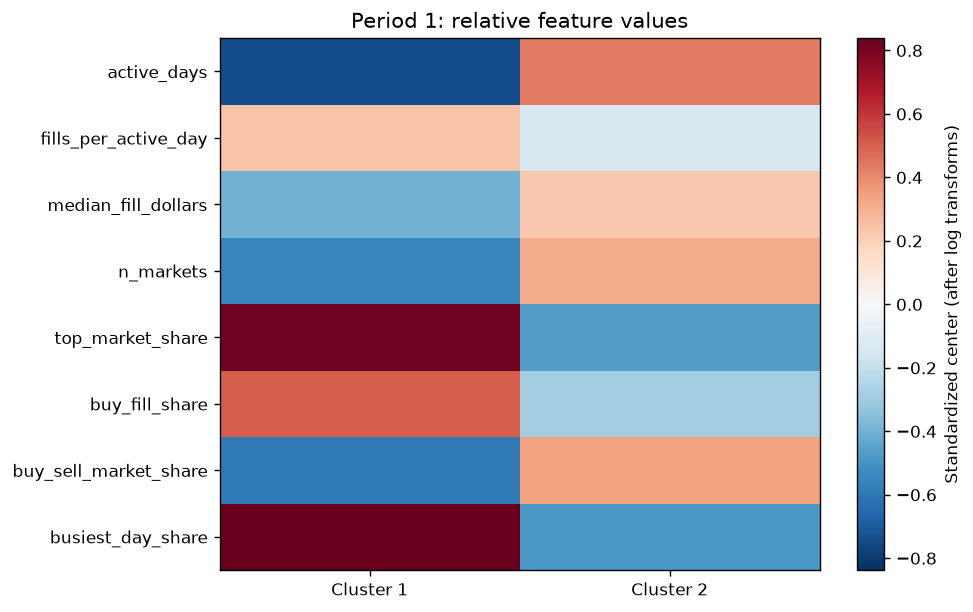

In [20]:
centers = cluster_model.cluster_centers_.T
color_limit = np.abs(centers).max()
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(centers, cmap="RdBu_r", vmin=-color_limit, vmax=color_limit, aspect="auto")
ax.set_xticks(range(selected_k), [f"Cluster {i}" for i in range(1, selected_k + 1)])
ax.set_yticks(range(len(cluster_features)), cluster_features)
ax.set_title("Period 1: relative feature values")
fig.colorbar(image, ax=ax, label="Standardized center (after log transforms)")
fig.tight_layout()
plt.show()


### 5. Apply the same profiles to later periods

Predict periods 2–6 with the period-1 scaler and model, without refitting. `wallet_profiles` contains one row per wallet and period, including periods without observed trades. Status counts use all wallets observed anywhere in the 24 weeks.

`first_observed` means first seen within this study, not a newly created wallet. Unobserved and insufficient-activity periods receive no cluster assignment.


In [21]:
cluster_labels = clustering_data[["wallet", "period"]].copy()
cluster_labels["cluster"] = cluster_model.predict(X_all) + 1

wallet_profiles = pd.MultiIndex.from_product(
    [wallet_features["wallet"].unique(), range(1, 7)],
    names=["wallet", "period"],
).to_frame(index=False)
wallet_profiles = wallet_profiles.merge(
    wallet_features[["wallet", "period", "n_fills", "active_days"]],
    on=["wallet", "period"], how="left",
)
wallet_profiles = wallet_profiles.merge(cluster_labels, on=["wallet", "period"], how="left")
wallet_profiles["cluster"] = wallet_profiles["cluster"].astype("Int64")
wallet_profiles["status"] = "Insufficient activity"
wallet_profiles.loc[wallet_profiles["n_fills"].isna(), "status"] = "No observed trades"
wallet_profiles.loc[wallet_profiles["cluster"].notna(), "status"] = "Profiled"

first_period = wallet_features.groupby("wallet")["period"].min()
wallet_profiles["first_observed"] = wallet_profiles["period"] == wallet_profiles["wallet"].map(first_period)
wallet_profiles["profile"] = wallet_profiles["cluster"].map(profile_names)
wallet_profiles = wallet_profiles[["wallet", "period", "cluster", "profile", "status", "first_observed"]]

period_status = pd.crosstab(wallet_profiles["period"], wallet_profiles["status"])
period_status["First observed in study"] = wallet_profiles.groupby("period")["first_observed"].sum()
period_status


status,Insufficient activity,No observed trades,Profiled,First observed in study
period,,,,
1,114576,758267,20139,134715
2,120042,749110,23830,86403
3,177164,674879,40939,134493
4,179683,654560,58739,109594
5,221040,624139,47803,114243
6,377720,342633,172629,313534


In [22]:
profile_counts = pd.crosstab(cluster_labels["period"], cluster_labels["cluster"])
profile_counts


cluster,1,2
period,,
1,7316,12823
2,7761,16069
3,16298,24641
4,19805,38934
5,20198,27605
6,91431,81198


### 6. Compare profiles across periods

Transitions compare wallets profiled in both adjacent periods. The same-profile rate is conditional on that group, not a retention rate for all wallets. The follow-up status table separately counts wallets with insufficient activity or no observed trades. Period-wide profile counts above also include first-observed wallets.

Adjacent comparisons share periods and wallets; they are not independent replications.


In [23]:
profiles_wide = wallet_profiles.pivot(index="wallet", columns="period", values="cluster")
statuses_wide = wallet_profiles.pivot(index="wallet", columns="period", values="status")
cluster_ids = range(1, selected_k + 1)
transition_counts = {}
transition_rates = {}
followup_tables = {}
transition_rows = []

for earlier in range(1, 6):
    later = earlier + 1
    label = f"{earlier} to {later}"
    paired = profiles_wide[[earlier, later]].dropna().astype(int)
    counts = pd.crosstab(paired[earlier], paired[later]).reindex(
        index=cluster_ids, columns=cluster_ids, fill_value=0
    )
    transition_counts[label] = counts
    transition_rates[label] = 100 * counts.div(counts.sum(axis=1), axis=0)

    origin_profiled = profiles_wide[earlier].notna()
    followup_tables[label] = pd.crosstab(
        profiles_wide.loc[origin_profiled, earlier],
        statuses_wide.loc[origin_profiled, later],
    ).reindex(
        index=cluster_ids,
        columns=["Profiled", "Insufficient activity", "No observed trades"],
        fill_value=0,
    )
    transition_rows.append({
        "periods": label,
        "origin_wallets": int(origin_profiled.sum()),
        "paired_wallets": len(paired),
        "profiled_again_pct": 100 * len(paired) / origin_profiled.sum(),
        "same_profile_pct": 100 * paired[earlier].eq(paired[later]).mean(),
    })

transition_summary = pd.DataFrame(transition_rows).set_index("periods")
transition_summary.round(2)


,origin_wallets,paired_wallets,profiled_again_pct,same_profile_pct
periods,,,,
1 to 2,20139,9510,47.22,76.93
2 to 3,23830,10431,43.77,81.41
3 to 4,40939,25246,61.67,74.27
4 to 5,58739,27620,47.02,73.52
5 to 6,47803,31197,65.26,78.02


In [24]:
followup_status = pd.concat(followup_tables, names=["periods", "origin_cluster"])
followup_status


Profiled  Insufficient activity  No observed trades
periods origin_cluster                                                     
1 to 2  1                   2407                   2538                2371
        2                   7103                   3065                2655
2 to 3  1                   2528                   2386                2847
        2                   7903                   2990                5176
3 to 4  1                   7388                   3922                4988
        2                  17858                   2693                4090
4 to 5  1                   5462                   5812                8531
        2                  22158                  10696                6080
5 to 6  1                   9720                   4175                6303
        2                  21477                   4470                1658

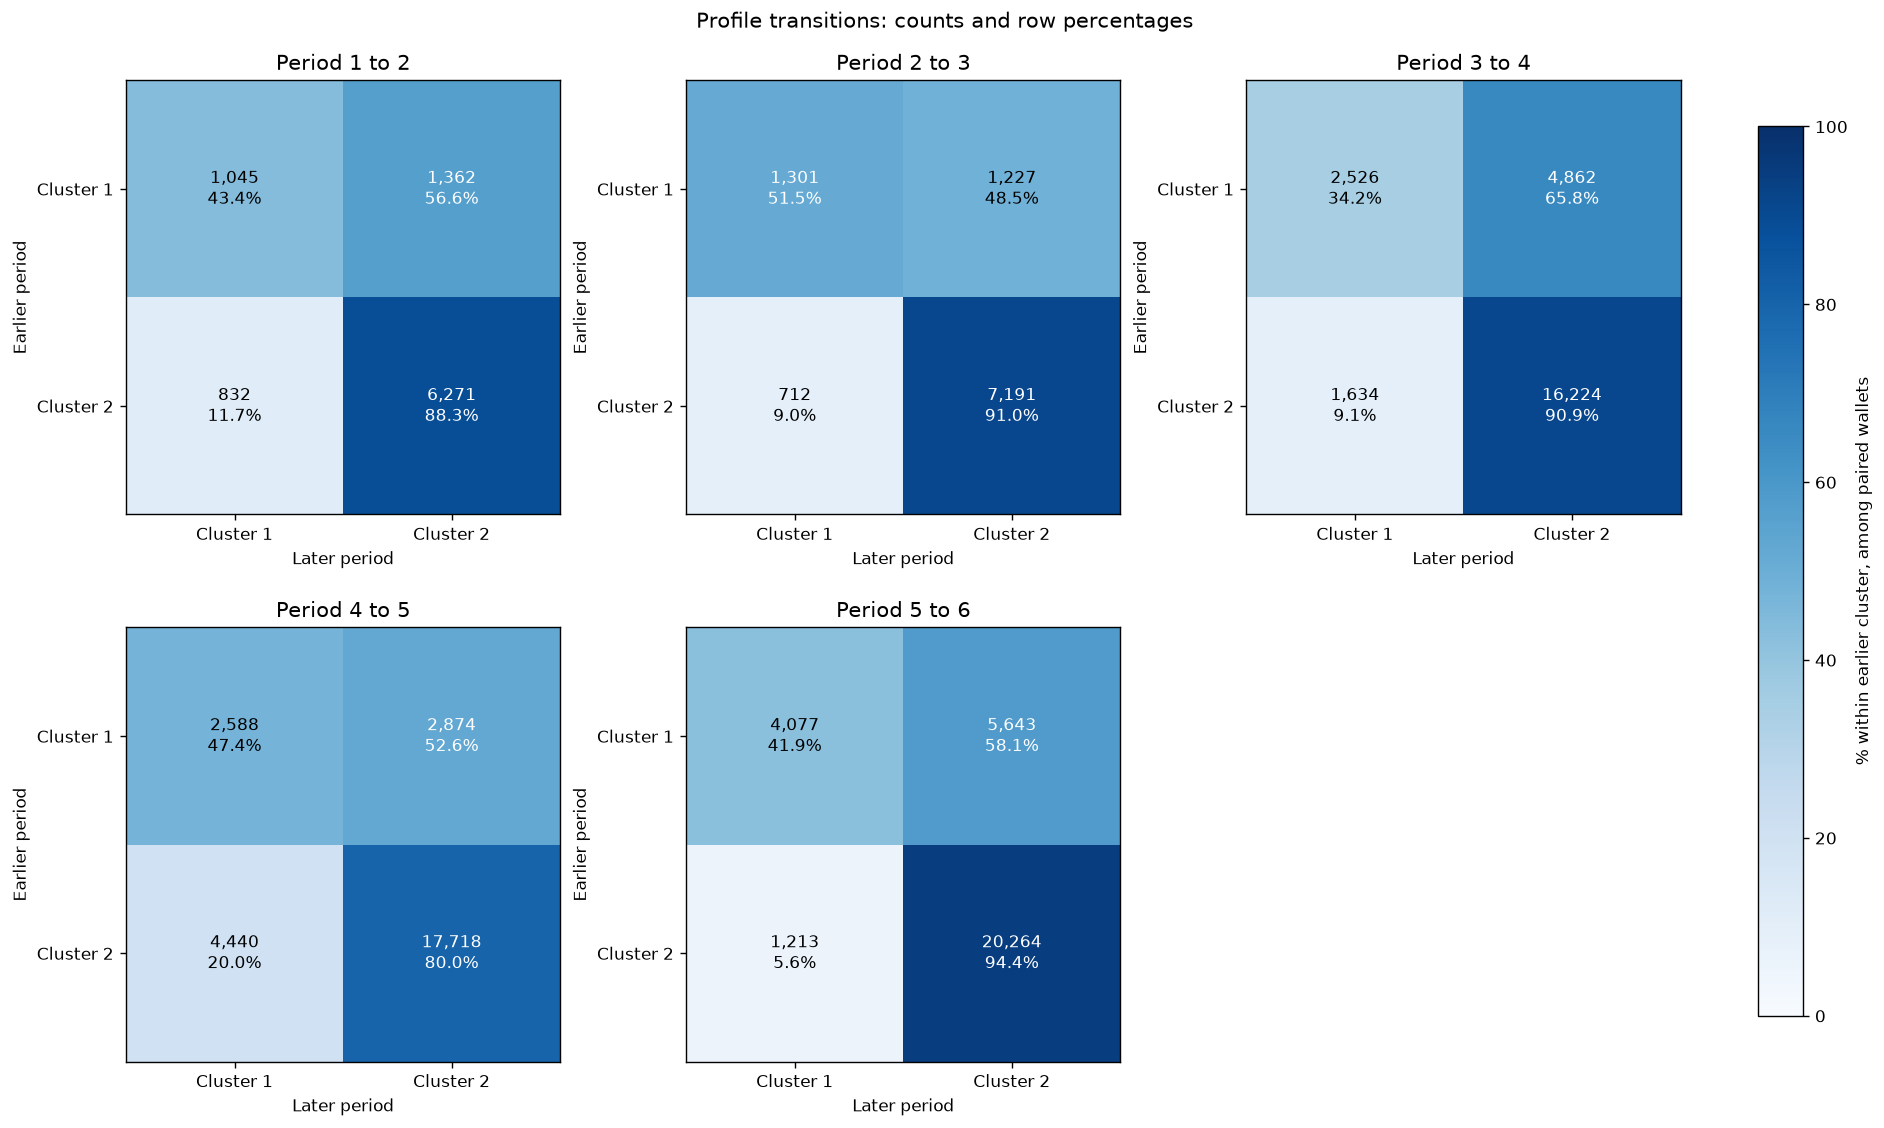

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")

for ax, label in zip(axes.flat, transition_counts):
    counts = transition_counts[label]
    rates = transition_rates[label]
    image = ax.imshow(rates, cmap="Blues", vmin=0, vmax=100)
    for row in range(selected_k):
        for column in range(selected_k):
            value = rates.iloc[row, column]
            ax.text(column, row, f"{counts.iloc[row, column]:,}\n{value:.1f}%",
                    ha="center", va="center", color="white" if value > 50 else "black")
    ax.set_xticks(range(selected_k), [f"Cluster {i}" for i in cluster_ids])
    ax.set_yticks(range(selected_k), [f"Cluster {i}" for i in cluster_ids])
    ax.set_xlabel("Later period")
    ax.set_ylabel("Earlier period")
    ax.set_title(f"Period {label}")

axes.flat[-1].set_visible(False)
fig.colorbar(image, ax=axes.ravel().tolist(), label="% within earlier cluster, among paired wallets", shrink=0.85)
fig.suptitle("Profile transitions: counts and row percentages")
plt.show()


`wallet_profiles` is the output for later market-event analysis. Profile changes indicate changes in these measured behaviors; they do not establish a change in intent or identity.


In [26]:
wallet_profiles.head(6)


,wallet,period,cluster,profile,status,first_observed
0,0x000025e0e96474e2485e259558e53f2dd4a54626,1,<NA>,NaN,No observed trades,False
1,0x000025e0e96474e2485e259558e53f2dd4a54626,2,<NA>,NaN,No observed trades,False
2,0x000025e0e96474e2485e259558e53f2dd4a54626,3,<NA>,NaN,No observed trades,False
3,0x000025e0e96474e2485e259558e53f2dd4a54626,4,<NA>,NaN,No observed trades,False
4,0x000025e0e96474e2485e259558e53f2dd4a54626,5,<NA>,NaN,No observed trades,False
5,0x000025e0e96474e2485e259558e53f2dd4a54626,6,1,"Less active, more concentrated",Profiled,True
